In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'

# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from tqdm import tqdm
from pathlib import Path

print(jax.devices())
jax.config.update("jax_debug_nans", True)

from config import Config
import data

[CpuDevice(id=0)]


In [3]:
save_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/data/multigraph_manual")
metadata_dir = save_dir / "metadata"

gauges = pd.read_parquet(metadata_dir / "gauge_matchups.parquet")
gauges

,is_gauge,uparea_km2,outlet_id,original_comid,COMID_v07,COMID,reach_id
site_id,,,,,,,
EAUF-A3750050,True,50400.618565,EAUF-A3750050,23013609,23014875,23014875.0,2.326700e+10
EAUF-A3020090,True,49816.201840,EAUF-A3750050,23013612,23016185,23016185.0,2.326700e+10
EAUF-A3020090,True,49816.201840,EAUF-A3750050,23013612,23016185,23016185.0,2.326700e+10
EAUF-A3550050,True,48408.708755,EAUF-A3750050,23013614,23016187,23016187.0,2.326700e+10
EAUF-A0610050,True,44103.666745,EAUF-A3750050,23013624,23016197,23016197.0,2.326700e+10
...,...,...,...,...,...,...,...
USGS-15744500,True,24449.325008,USGS-15744500,81006772,81007789,81007789.0,8.132030e+10
USGS-15747000,True,1849.329060,USGS-15747000,81003724,81005569,81005569.0,8.135010e+10
USGS-15747000,True,1849.329060,USGS-15747000,81003724,81005569,81005569.0,8.135010e+10


In [4]:
cfg = Config.from_file("/nas/cee-water/cjgleason/ted/swot-ml/runs/test/swot_vD.yml")
cfg.quiet = False

In [5]:
dataset = data.MCFLIDataset(cfg, 'train')
dataset

100%|██████████| 1454/1454 [06:42<00:00,  3.61it/s] 


In [6]:
dataset.hws.shape

(1830, 150, 3)

In [12]:
l = ('A0', 'n')
[x for x in reversed(l)]

['n', 'A0']

In [197]:
import xarray as xr
import jax.numpy as jnp
import numpy as np

self = dataset
basins = self.basins
features = cfg.features.dynamic['swot-river']
targets = cfg.features.target

pad_size = 100

basin_list = []
site_list = []
x_list = []
y_list = []
hws_list = []
mask_list = []

for b in tqdm(basins):
    sites = list(self.basin_subset_dict[b])
    
    ds = xr.open_zarr(cfg.zarr_dir / b)

    try:
        ds_subset = ds.sel(subbasin=sites, date=self.time_slice)
        x = ds_subset[features]
        y = ds_subset[targets]
    except KeyError:
        continue

    valid_features = ~np.isnan(x[features[0]].values)
    valid_target =  ~np.isnan(y.to_array().values[0,...])
    valid_mask = valid_features & valid_target

    for s_idx in range(valid_mask.shape[1]):
        t_ids = np.where(valid_mask[:,s_idx])[0]
        if len(t_ids) == 0:
            continue
        else:
            subbasin_id = x.subbasin.values[s_idx]

            x_arr = x.isel(date=t_ids, subbasin=s_idx).to_array().values.T # [time, features]
            y_arr = y.isel(date=t_ids, subbasin=s_idx).to_array().values.T # [time, features]


            pos_width = x_arr[:, features.index('width_river')]>0
            pos_slope = x_arr[:, features.index('slope_river')]>0
            valid_indices = np.where(pos_width & pos_slope)[0]

            if len(valid_indices)<5:
                continue
                
            # Sub-select only physically valid timesteps
            x_arr = x_arr[valid_indices, :]
            y_arr = y_arr[valid_indices, :]
            n_samples, n_features = x_arr.shape


            if n_samples > pad_size:
                raise ValueError(f"pad_size ({pad_size}) exceeded by {n_samples} samples.")
            
            # Padding logic
            x_pad = np.zeros((pad_size, n_features), dtype=x_arr.dtype)
            x_pad[:n_samples, :] = x_arr
            
            mask = np.zeros((pad_size, n_features), dtype=bool)
            mask[:n_samples, :] = 1
            
            y_pad = np.zeros((pad_size, y_arr.shape[1]), dtype=y_arr.dtype)
            y_pad[:n_samples, :] = y_arr

            hws_cols = ['d_wse_river', 'width_river', 'slope_river']
            hws_ids = [features.index(c) for c in hws_cols]
            hws_pad = x_pad[:, hws_ids]


            basin_list.append(b)
            site_list.append(subbasin_id)
            x_list.append(x_pad)
            y_list.append(y_pad)
            hws_list.append(hws_pad)
            mask_list.append(mask)

    if len(basin_list) >= 3:
        break


x = np.stack(x_list)
y = np.stack(y_list)
hws = np.stack(hws_list)
mask = np.stack(mask_list)


  1%|          | 14/1454 [00:01<02:08, 11.22it/s]


(4, 100, 15)

In [160]:
valid_indices

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

In [157]:
pos_slope.shape

(10,)

In [55]:
x_dynamic = d[self.source_columns]  # keep as DataArray for coords
y = ds[self.target]

valid_features = ~np.isnan(x_dynamic[self.source_columns[0]].values)
valid_target = ~np.isnan(y.to_array().values[0,...])
valid_mask = valid_features & valid_target

(array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1]),
 array([ 329,  349,  370,  391,  537,  642,  683,  746, 1017, 1038]))

In [4]:
from torch.utils.data import Dataset, DataLoader

class FlatObservationDataset(Dataset):
    def __init__(self, train_sites, test_sites):
        if source_name not in self.features.dynamic:
            raise ValueError(f"Source '{source_name}' not found in config dynamic sources.")
        self.train_sites = train_sites
        self.test_sites = test_sites
        self.samples = []

        for 
            
            #     x_dynamic = ds[self.source_columns]  # keep as DataArray for coords
            #     y = ds[self.target]
            
            #     valid_features = ~np.isnan(x_dynamic[self.source_columns[0]].values)
            #     valid_target = ~np.isnan(y.to_array().values[0,...])
            #     valid_mask = valid_features & valid_target
        
            #     for s_idx in range(valid_mask.shape[1]):
            #         t_ids = np.where(valid_mask[:,s_idx])[0]
            #         if len(t_ids) == 0:
            #             continue
            #         else:
            #             subbasin_id = x_dynamic.subbasin.values[s_idx]

            #             x_s = self.x_s.sel(subbasin=subbasin_id)[self.features.static].to_array().values.astype(np.float32)
                        
            #             # Extract raw (normalized) data for current reach
            #             x_d_raw = x_dynamic.isel(date=t_ids, subbasin=s_idx).to_array().values.T
            #             y_arr_raw = y.isel(date=t_ids, subbasin=s_idx).to_array().values.T

            #             # Extract and denormalize width and slope for filtering
            #             # Width is index 1, Slope is index 2 in hws_cols
            #             w_denorm = self.denormalize(x_dynamic['width_river'].isel(date=t_ids, subbasin=s_idx).values, 'width_river')
            #             s_denorm = self.denormalize(x_dynamic['slope_river'].isel(date=t_ids, subbasin=s_idx).values, 'slope_river')

            #             reach_q_b_1 = x_dynamic['reach_q_river_bit_1'].isel(date=t_ids, subbasin=s_idx).values

                        
            #             # Identify valid indices where denormalized width and slope > 0
            #             physical_mask = (w_denorm > 0) & (s_denorm > 0) & (reach_q_b_1 == 0)
            #             valid_t_indices = np.where(physical_mask)[0]
                        
            #             if len(valid_t_indices) == 0:
            #                 continue

            #             # Sub-select only physically valid timesteps
            #             x_d = x_d_raw[valid_t_indices]
            #             y_arr = y_arr_raw[valid_t_indices]
            #             n_samples, n_features = x_d.shape
                        
            #             if n_samples > pad_size:
            #                 raise ValueError(f"pad_size ({pad_size}) exceeded by {n_samples} samples.")
                        
            #             # Padding logic
            #             x_pad = np.ones((pad_size, n_features), dtype=x_d.dtype)
            #             x_pad[:n_samples, :] = x_d
                        
            #             mask = np.zeros((pad_size, n_features), dtype=np.int8)
            #             mask[:n_samples, :] = 1
                        
            #             y_pad = np.ones((pad_size, y_arr.shape[1]), dtype=x_d.dtype)
            #             y_pad[:n_samples, :] = y_arr
                        
            #             # Construct hws with denormalized values for valid indices
            #             hws_cols = ['d_wse_river', 'width_river', 'slope_river']
            #             hws_arr = x_dynamic[hws_cols].isel(date=t_ids, subbasin=s_idx).to_array().values.T[valid_t_indices]
                        
            #             for i, col in enumerate(hws_cols):
            #                 hws_arr[:, i] = self.denormalize(hws_arr[:, i], col)
                        
            #             hws_pad = np.ones((pad_size, hws_arr.shape[1]), dtype=x_d.dtype)
            #             hws_pad[:n_samples, :] = hws_arr
                        
            #             reach_sample = {
            #                 'basin': basin,
            #                 'subbasin': subbasin_id,
            #                 'x_d': x_pad,
            #                 'd_mask': mask,
            #                 'x_s': x_s,
            #                 'hws': hws_pad,
            #                 'y': y_pad 
            #             }
            #             self.samples.append(reach_sample)


            # # break

        
    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx: int):
        return self.samples[idx]
        

train_dataset = FlatObservationDataset(cfg, train_cache_dir, 200, 'train', 'swot-river')

Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for train...Done!


Caching basins in memory: 100%|██████████| 1454/1454 [11:43<00:00,  2.07it/s]


In [5]:
from torch.utils.data import DataLoader

def collate_flat_jax(samples):
    basin = [s['basin'] for s in samples]
    subbasin = [s['subbasin'] for s in samples]
    x_d = jnp.array([s['x_d'] for s in samples])
    d_mask = jnp.array([s['d_mask'] for s in samples])
    x_s = jnp.array([s['x_s'] for s in samples])
    hws = jnp.array([s['hws'] for s in samples])
    y = jnp.array([s['y'] for s in samples])
    return basin, subbasin, x_d, d_mask, x_s, hws, y

# train_dataset = FlatObservationDataset(cfg, train_cache_dir, 'train', 'swot-river')
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=collate_flat_jax)

In [186]:
import equinox as eqx

class ReachParameterNet(eqx.Module):
    A0_net: eqx.nn.MLP
    n_net: eqx.nn.MLP

    def __init__(self, in_size, hidden_size, depth, *, key):
        k1, k2 = jax.random.split(key)
        # Separate heads to eliminate parameter interference
        self.A0_net = eqx.nn.MLP(
            in_size=in_size,
            out_size=1,
            width_size=hidden_size,
            depth=depth,
            key=k1
        )
        self.n_net = eqx.nn.MLP(
            in_size=in_size,
            out_size=1,
            width_size=hidden_size,
            depth=depth,
            key=k2
        )
    
    def __call__(self, x_d, d_mask, x_s, hws):

        def get_params(x_temporal):
            feat = jnp.concat([x_temporal, x_s])
            return jnp.concat([self.A0_net(feat), self.n_net(feat)])

        embeddings = jax.vmap(get_params)(x_d)
        params = jnp.mean(embeddings, axis=0, where=d_mask[:, None])

        dh = hws[:, 0]
        w = hws[:, 1]
        s = hws[:, 2]
        dA = w * dh

        # A0 scaled by mean width to provide physical context
        avg_w = jnp.mean(w, where=d_mask)
        A0_depth = jax.nn.softplus(params[0]) 
        A0 = (A0_depth * avg_w) - jnp.min(dA) + 1e-6
        A = A0 + dA

        # soft, symmetric mapping of latent states 
        n_center = 0.3     
        n_half_range = 0.299
        n = n_center + n_half_range * jnp.tanh(params[1])

        Q = (1/n) * jnp.power(A, 5/3) * jnp.power(w, -2/3) * jnp.sqrt(s)

        return Q, A0, n


@eqx.filter_value_and_grad
def log_mse_loss(model, x_d, d_mask, x_s, hws, y, norm_fn):
    y_hat, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws)
    err = norm_fn(y_hat) - y
    return jnp.nanmean(jnp.nanmean(err**2, axis=1, where=d_mask))

@eqx.filter_value_and_grad
def log_mae_loss(model, x_d, d_mask, x_s, hws, y, norm_fn):
    y_hat, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws)
    err = norm_fn(y_hat) - y
    return jnp.nanmean(jnp.nanmean(jnp.abs(err), axis=1, where=d_mask))

@eqx.filter_value_and_grad
def nse_loss(model, x_d, d_mask, x_s, hws, y, denorm_fn):
    y_hat, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws)
    y_obs = target_denorm_fn(y)
    
    sq_error = jnp.abs(y_obs - y_hat)
    numer = jnp.sum(sq_error, axis=1, where=d_mask)
    
    y_obs_mean = jnp.mean(y_obs, axis=1, where=d_mask)
    sq_dev = jnp.abs((y_obs - y_obs_mean[:,jnp.newaxis]))
    denom = jnp.sum(sq_dev, axis=1, where=d_mask) + 0.1

    NSE = 1 - jnp.mean(numer / denom)

    NNSE = 1 / (2-NSE)
    NNSE
    
    return 1 - NNSE




In [7]:
sample = train_dataset[0]
d_size = sample['x_d'].shape[-1]
s_size = sample['x_s'].shape[-1]

in_size = d_size + s_size
out_size = 1

In [8]:
for batch in train_loader:
    basin, subbasin, x_d, d_mask, x_s, hws, y = batch
    d_mask = d_mask[..., 0] #bandaid
    y = y[...,0]
    break

key = jax.random.PRNGKey(0)
tmp_model = ReachParameterNet(in_size, 128, 2, key=key)

y_hat, A0, n = jax.vmap(tmp_model)(x_d, d_mask, x_s, hws)

In [159]:
numer / denom

Array([  1.0821865 ,  24.42132   ,   3.0533335 ,   2.8246212 ,
        35.99326   ,   2.1553688 ,   5.444722  ,   1.4443604 ,
         4.341093  ,   1.6032157 ,   0.9796115 ,   1.8780746 ,
         1.4582702 ,   0.734623  ,   3.2682831 ,   0.56260276,
         3.1370082 ,   1.812816  ,  11.089133  ,   1.6448612 ,
       112.234436  ,  18.045725  ,   2.0615463 ,  39.75659   ,
         2.589072  ,   1.4420589 ,  10.625388  ,   1.129193  ,
         0.68955964,   1.2579663 ,   1.3466483 ,   1.290757  ,
         3.0233665 ,   1.2160828 , 539.04926   ,   1.3063073 ,
         2.4061863 ,   3.6960459 ,   2.9037244 ,   1.7627401 ,
         4.490156  ,   1.5926344 ,   1.1381457 ,   1.9653513 ,
         1.4038808 ,   1.206881  ,   3.171125  ,  15.279566  ,
         1.1816823 ,   9.779325  ,   1.5171788 ,  11.947872  ,
         2.3681464 ,   3.6044521 ,   1.1429923 ,  44.06592   ,
         1.2574296 ,  20.363531  ,   0.81281126,   2.8009806 ,
         0.8245691 ,  20.718485  ,   5.7799654 ,   6.08

In [155]:
loss, grads = nse_loss(model, x_d, d_mask, x_s, hws, y, target_denorm_fn)

loss

Array(15.957199, dtype=float32)

In [138]:
denom

Array([2.89136384e+08, 4.00444719e+05, 4.93920625e+04, 1.35764125e+05,
       1.17506875e+04, 1.67979109e+05, 4.56916875e+05, 6.42786375e+05,
       8.43475078e+04, 4.38153850e+06, 6.86397266e+03, 9.84403906e+04,
       1.35960129e+02, 3.27493555e+04, 2.88083750e+04, 3.84868531e+05,
       2.12093812e+05, 9.49721741e+02, 3.63040062e+05, 3.44677500e+04,
       4.83687281e+05, 3.69331719e+04, 1.07483008e+05, 8.06216553e+03,
       1.18700890e+07, 1.30429370e+07, 1.13131788e+06, 1.15593800e+06,
       7.53435688e+05, 6.24636125e+05, 2.36298301e+04, 0.00000000e+00,
       3.18209812e+05, 2.06914016e+05, 1.61710580e+07, 2.26389950e+06,
       6.90817375e+05, 8.87726855e+03, 2.31950117e+04, 7.01749812e+05,
       2.19298262e+04, 1.29622617e+05, 6.27022969e+04, 2.41780273e+03,
       5.05301219e+05, 2.18930320e+07, 8.17188873e+01, 1.33463652e+04,
       6.01093750e+02, 7.07277000e+05, 1.47000250e+06, 5.13351688e+05,
       5.06808031e+05, 2.47023920e+07, 1.80557875e+05, 4.18353828e+04,
      

In [193]:
import optax
from functools import partial

jax.config.update("jax_debug_nans", True)

key = jax.random.PRNGKey(0)
model = ReachParameterNet(in_size, 256, 4, key=key)

optim = optax.adamw(learning_rate=0.001, weight_decay=0.1)
trainable_model = eqx.filter(model, eqx.is_array)
opt_state = optim.init(trainable_model)


@eqx.filter_jit
def make_step(model, x_d, d_mask, x_s, hws, y, norm_fn, denorm_fn, opt_state):
    loss, grads = log_mse_loss(model, x_d, d_mask, x_s, hws, y, norm_fn)
    # loss, grads = log_mae_loss(model, x_d, d_mask, x_s, hws, y, norm_fn)
    # loss, grads = nse_loss(model, x_d, d_mask, x_s, hws, y, denorm_fn)
    updates, opt_state = optim.update(grads, opt_state, params=model)
    model = eqx.apply_updates(model, updates)
    return loss, model, opt_state


losses = []
target_norm_fn = partial(train_dataset.normalize, name='discharge')
target_denorm_fn = partial(train_dataset.denormalize, name='discharge')

epoch_iter = tqdm(range(250), desc='Epoch:')
for epoch in epoch_iter:
    e_losses = []
    for batch in train_loader:
        basin, subbasin, x_d, d_mask, x_s, hws, y = batch
        d_mask = d_mask[..., 0] #bandaid
        y = y[...,0]

        loss, model, opt_state = make_step(model, x_d, d_mask, x_s, hws, y, target_norm_fn, target_denorm_fn, opt_state)
        e_losses.append(loss.item())
    
    loss = np.mean(e_losses)
    losses.append(loss)

    epoch_iter.set_postfix_str(f"{loss = :0.4f}")


Epoch:: 100%|██████████| 250/250 [02:47<00:00,  1.49it/s, loss = 0.4944]


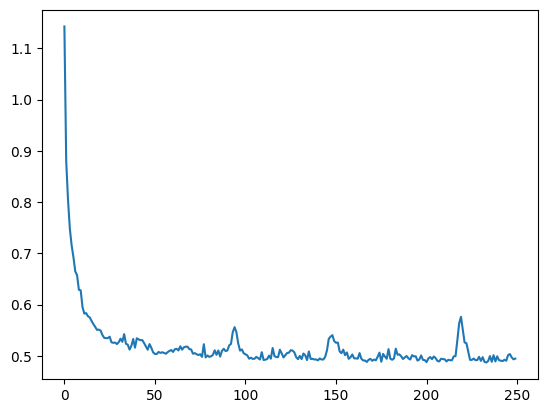

In [196]:
plt.plot(losses)

Array([[1.18481426e+01, 9.59868908e+00, 1.95274448e+01, ...,
        4.97318115e+03, 4.97318115e+03, 4.97318115e+03],
       [1.03976181e+02, 1.06196594e+02, 1.02010468e+02, ...,
        8.37443984e+04, 8.37443984e+04, 8.37443984e+04],
       [2.02085185e+00, 1.18104231e+00, 1.61575854e+00, ...,
        2.65588989e+02, 2.65588989e+02, 2.65588989e+02],
       ...,
       [5.64944496e+01, 4.54925652e+01, 4.86977005e+01, ...,
        8.12331934e+03, 8.12331934e+03, 8.12331934e+03],
       [3.09843242e-01, 4.12309974e-01, 3.84333432e-01, ...,
        2.55019821e+02, 2.55019821e+02, 2.55019821e+02],
       [1.73855270e+02, 1.92855606e+02, 1.78730179e+02, ...,
        5.06857406e+05, 5.06857406e+05, 5.06857406e+05]], dtype=float32)

In [194]:
y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws)

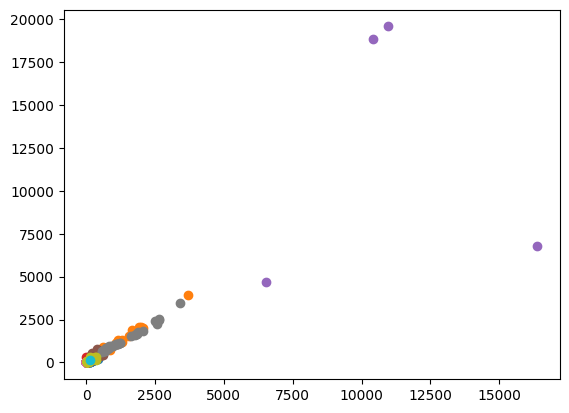

In [195]:
y_denorm = train_dataset.denormalize(y, 'discharge')


for reach_idx in range(10):
    reach_idx += 0
    mask_ids = np.where(d_mask[reach_idx, :])
    y_h = y_hat[reach_idx, mask_ids]
    y_o = y_denorm[reach_idx, mask_ids]

    plt.scatter(y_o, y_h)


(array([10.,  6.,  0.,  2.,  0.,  0.,  0.,  1.,  0.,  7.]),
 array([0.02030537, 0.07817483, 0.13604429, 0.19391374, 0.25178322,
        0.30965269, 0.36752212, 0.42539158, 0.48326105, 0.54113054,
        0.59899998]),
 <BarContainer object of 10 artists>)

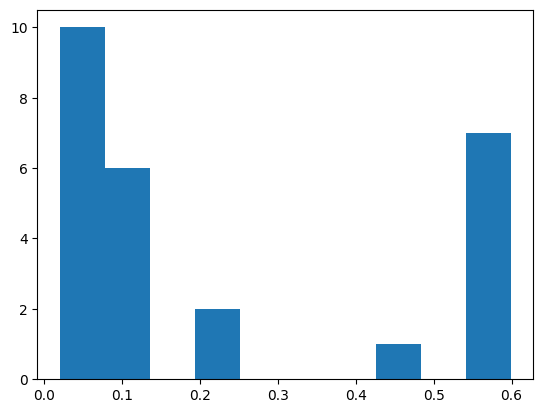

In [197]:
plt.hist(n)

In [198]:
test_cache_dir = cache_mgr.create_cache('test')
test_dataset = FlatObservationDataset(cfg, train_cache_dir, 200, 'test', 'swot-river')
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=True, collate_fn=collate_flat_jax)

Calculating training statistics for encoding and normalization...


Caching test: 100%|██████████| 278/278 [02:49<00:00,  1.64it/s]


Wrote 278 new Zarr files.
✅ Saved 172371 indices to /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache2/a095b90be9006a4a/test/_indices/sequence=90
All caches created and indexed.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for test...Done!


Caching basins in memory: 100%|██████████| 278/278 [06:16<00:00,  1.36s/it]


In [199]:
subbasin_list = []
y_list = []
y_pred_list = []
A0_list = []
n_list = []
h_list = []
w_list = []
s_list = []

for batch in tqdm(train_loader):
    basin, subbasin, x_d, d_mask, x_s, hws, y = batch
    d_mask = d_mask[..., 0] #bandaid
    y = y[...,0]

    y_hat, A0, n = jax.vmap(model)(x_d, d_mask, x_s, hws)

    y = test_dataset.denormalize(y, 'discharge')

    for i in range(y.shape[0]):
        mask_ids = np.where(d_mask[i,:])[0]
        n_obs = len(mask_ids)

        subbasin_list.append(np.tile(subbasin[i], n_obs))
        y_list.append(y[i, mask_ids])
        y_pred_list.append(y_hat[i, mask_ids])
        A0_list.append(np.tile(A0[i], n_obs))
        n_list.append(np.tile(n[i], n_obs))
        h_list.append(hws[i,mask_ids,0])
        w_list.append(hws[i,mask_ids,1])
        s_list.append(hws[i,mask_ids,2])

pred_data = {
    'subbasin': np.concatenate(subbasin_list),
    'Q_obs': np.concatenate(y_list),
    'Q_hat': np.concatenate(y_pred_list),
    'A0': np.concatenate(A0_list),
    'n': np.concatenate(n_list),
    'h': np.concatenate(h_list),
    'w': np.concatenate(w_list),
    's': np.concatenate(s_list),
}

results = pd.DataFrame(pred_data)

100%|██████████| 32/32 [01:13<00:00,  2.29s/it]


In [200]:
reach_avg = results.groupby('subbasin').mean()
reach_avg

,Q_obs,Q_hat,A0,n,h,w,s
subbasin,,,,,,,
ABOM-100288010,2.891333,3.982692,53.527027,0.598997,0.217633,46.736237,0.000817
ABOM-12049010,169.950302,66.897636,372.714752,0.598863,0.843033,215.417862,0.000495
ABOM-121206010,60.256020,27.841503,-0.999999,0.062519,0.453800,99.270203,0.002550
ABOM-122989010,189.294662,126.892006,171.395676,0.108692,0.363767,225.907547,0.000483
ABOM-123639010,355.208008,60.685650,317.572052,0.506023,0.616587,125.900780,0.000287
...,...,...,...,...,...,...,...
USGS-15580095,103.249352,76.723312,460.770630,0.368670,-0.064799,165.706573,0.000795
USGS-15744500,675.871338,5501.422852,26793.664062,0.599000,-0.141875,799.749146,0.000180
USGS-15747000,40.446239,18.777283,187.248978,0.599000,0.045418,191.478409,0.001576


In [201]:
results

,subbasin,Q_obs,Q_hat,A0,n,h,w,s
0,ABOM-184020010,227.284042,230.831116,151.815033,0.027088,0.8049,148.994904,0.000238
1,ABOM-184020010,210.932022,171.796127,151.815033,0.027088,0.4669,133.854599,0.000252
2,ABOM-184020010,80.543015,51.239784,151.815033,0.027088,-0.6268,99.468559,0.000277
3,ABOM-184020010,144.591034,127.700104,151.815033,0.027088,0.1550,121.308220,0.000261
4,ABOM-184020010,192.233963,173.607590,151.815033,0.027088,0.4883,148.814529,0.000254
...,...,...,...,...,...,...,...,...
65291,USGS-08396500,18.434269,8.215005,65.448837,0.415837,0.0287,13.776750,0.000334
65292,USGS-08396500,4.559012,3.604748,65.448837,0.415837,-0.7912,22.126713,0.000349
65293,USGS-08396500,6.116439,34.061665,65.448837,0.415837,1.0691,578.687683,0.000343
65294,USGS-08396500,39.077248,23.510378,65.448837,0.415837,1.0147,408.204132,0.000335


In [202]:
results.to_parquet('./reach_parameter_results.parquet')

In [203]:
from evaluate import metrics

def get_nse(grp):
    y = grp['Q_obs']
    y_pred = grp['Q_hat']

    kge_results = metrics.calc_kge(y, y_pred)
    if isinstance(kge_results, tuple):
        kge, corr, alpha, beta = kge_results
    else:
        kge = corr = alpha = beta = np.nan
    out = {
        'kge': kge,
        'corr': corr,
        'alpha': alpha,
        'beta': beta
    }
    return pd.Series(out)
    
kge = results.groupby('subbasin').apply(get_nse, include_groups=False).dropna()
kge

,kge,corr,alpha,beta
subbasin,,,,
ABOM-100288010,-0.016232,0.886254,1.936651,1.377458
ABOM-12049010,-0.108994,0.294860,0.395880,0.393631
ABOM-121206010,0.191090,1.000000,0.395889,0.462053
ABOM-122989010,0.553471,0.925522,0.708167,0.670341
ABOM-123639010,-0.206678,0.971768,0.123731,0.170887
...,...,...,...,...
USGS-15565447,-0.160865,-0.159797,1.035722,0.965317
USGS-15580095,-0.138886,0.154381,0.281678,0.743088
USGS-15744500,-6.438591,0.181024,2.919873,8.139748


(-1.0, 1.0)

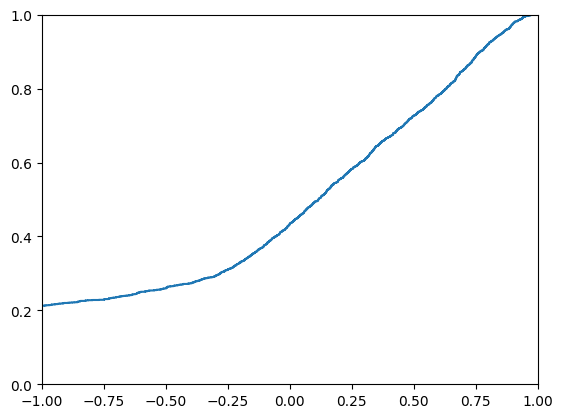

In [204]:
plt.ecdf(kge['kge'])
plt.xlim([-1,1])

In [3]:
def get_corr(grp):
    return np.corrcoef(grp['Q_pred'], grp['h'])[0, 1]

h_corr = results.groupby('subbasin').apply(get_corr, include_groups=False)
h_corr

NameError: name 'results' is not defined

In [206]:
kge.join(h_corr.rename('h_corr'))

NameError: name 'h_corr' is not defined

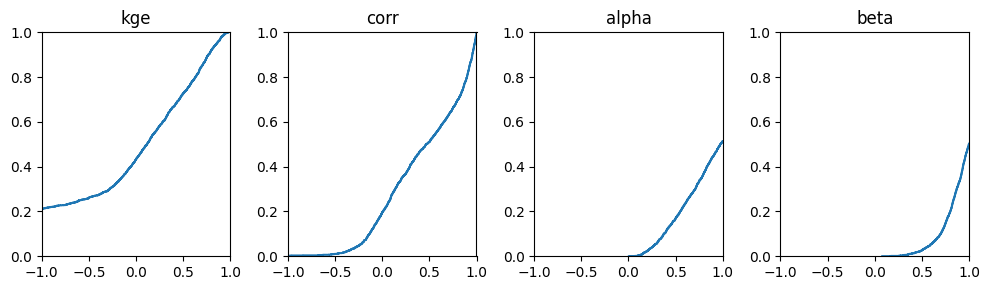

In [207]:
fig, axes = plt.subplots(1,4, figsize=(10,3))
for c, ax in zip(kge.columns, axes):
    y = kge[c]
    ax.ecdf(y)
    ax.set_xlim([-1, 1])
    ax.set_title(c)

fig.tight_layout()

In [77]:
kge['beta']

259.6788635253906

In [208]:
kge.sort_values('kge')

,kge,corr,alpha,beta
subbasin,,,,
USGS-06191500,-151264.518125,-0.136399,146657.515625,37056.679688
USGS-09105000,-111998.263764,-0.037554,111288.890625,12604.193359
USGS-09070000,-100970.981762,-0.078778,99068.914062,19517.390625
USGS-06326500,-82195.768111,-0.062354,81518.601562,10545.634766
USGS-08263500,-32367.337958,0.029937,30895.128906,9658.230469
...,...,...,...,...
BRANA-33286000,0.965466,0.967244,0.998209,0.989212
USGS-05369500,0.970042,0.971815,1.002758,1.009770
BRANA-66710000,0.971950,0.986466,0.975434,1.000367


<Axes: xlabel='h', ylabel='w'>

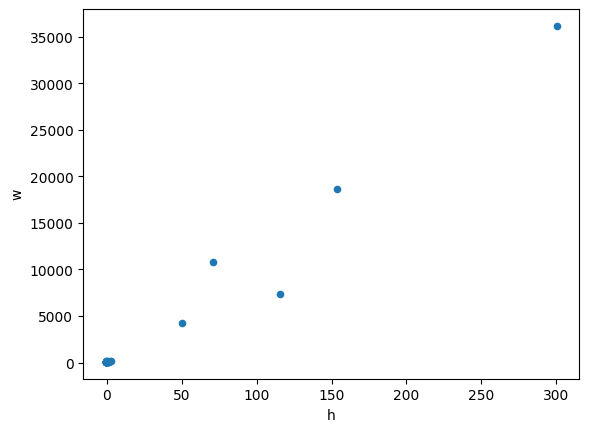

In [219]:
basin_results.plot.scatter('h','w')

<Axes: xlabel='Q_obs', ylabel='Q_hat'>

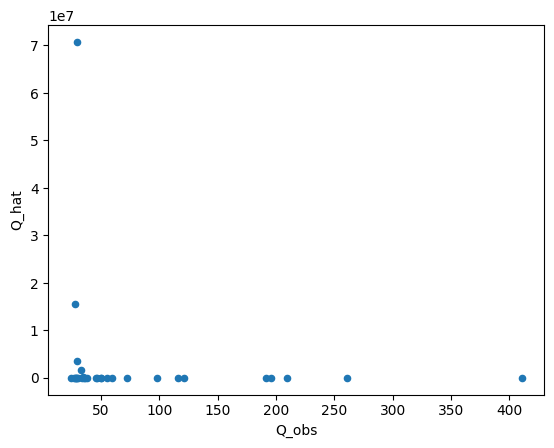

In [217]:
basin_results = results[results['subbasin'] == 'USGS-06191500']

basin_results.plot.scatter('Q_obs','Q_hat')

In [215]:
basin_results

,subbasin,y,y_pred,A0,n,h,w,s
762,ABOM-133975010,1.727000,33.094036,190.599609,0.295931,-0.9093,47.417828,0.000971
763,ABOM-133975010,5.908000,33.226742,190.599609,0.295931,-0.6750,51.860363,0.000923
764,ABOM-133975010,15.640998,26.723200,190.599609,0.295931,-0.3652,77.347626,0.000883


In [168]:
y_obs

Array([ 460.4009 ,  421.3529 ,  338.98297,  304.862  ,  421.3529 ,
        384.53787, 2065.9692 , 2118.2292 , 2344.2092 , 1191.4497 ,
        984.8622 ,  507.94205,  420.52075,  314.83484,  240.09795,
        184.77193,  159.74292,  161.96196,  228.60191,  346.81085,
        369.27185,  653.14795,  911.5111 ], dtype=float32)